# 02 — Feature Engineering
**Input:** `data/train_FD001_with_rul.parquet` + `data/eda_meta.json`  
**Output:** `data/train_features.parquet` · `data/val_features.parquet` · `data/feature_meta.json`

Steps:
1. Load processed data & EDA metadata
2. Drop constant sensors
3. Build rolling-window features (window = 30 cycles)
4. Inspect feature matrix
5. Train / val split by engine (`GroupShuffleSplit`) — no data leakage
6. Save splits

## 0 · Imports & paths

In [13]:
import json
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit

logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s")
log = logging.getLogger(__name__)

ROOT      = Path("../").resolve()
DATA_PROC = ROOT / "data"

WINDOW       = 30   # rolling window size in cycles
RANDOM_STATE = 42
VAL_SIZE     = 0.2  # 20 % of engines go to validation

sns.set_theme(style="darkgrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

# ── Physical sensor names (Saxena et al., 2008 — CMAPSS variable definitions)
# Sensors 01, 05, 10, 16, 18, 19 are constant and dropped before this notebook.
SENSOR_LABELS = {
    "sensor_02": "LPC outlet temp (T24, °R)",
    "sensor_03": "HPC outlet temp (T30, °R)",
    "sensor_04": "LPT outlet temp (T50, °R)",
    "sensor_06": "Bypass-duct pressure (P15, psia)",
    "sensor_07": "HPC outlet pressure (P30, psia)",
    "sensor_08": "Physical fan speed (Nf, rpm)",
    "sensor_09": "Physical core speed (Nc, rpm)",
    "sensor_11": "HPC outlet static pressure (Ps30, psia)",
    "sensor_12": "Fuel flow / Ps30 ratio (phi)",
    "sensor_13": "Corrected fan speed (NRf, rpm)",
    "sensor_14": "Corrected core speed (NRc, rpm)",
    "sensor_15": "Bypass ratio (BPR)",
    "sensor_17": "Bleed enthalpy (htBleed)",
    "sensor_20": "HPT coolant bleed (W31)",
    "sensor_21": "LPT coolant bleed (W32)",
}

def feature_label(feat: str) -> str:
    """Map an engineered feature name like 'sensor_11_mean' to a readable label."""
    for key, name in SENSOR_LABELS.items():
        if feat.startswith(key):
            suffix = feat[len(key):]          # e.g. '_mean', '_std', '_lag1'
            return f"{name}{suffix}"
    return feat

## 1 · Load data & metadata

In [14]:
df = pd.read_parquet(DATA_PROC / "train_FD001_with_rul.parquet")

meta = json.loads((DATA_PROC / "eda_meta.json").read_text())
useful_sensors    = meta["useful_sensors"]
constant_sensors  = meta["constant_sensors"]
RUL_CLIP          = meta["rul_clip"]

log.info("Loaded training data: %s rows, %s cols", *df.shape)
log.info("Useful sensors  : %d", len(useful_sensors))
log.info("Constant sensors: %d (will drop)", len(constant_sensors))
df.head(3)

INFO | Loaded training data: 20631 rows, 27 cols
INFO | Useful sensors  : 15
INFO | Constant sensors: 6 (will drop)


,unit_id,cycle,op_set_1,op_set_2,op_set_3,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,rul
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,125
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,125
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,125


## 2 · Drop constant sensors

In [15]:
def drop_constant_sensors(
    df: pd.DataFrame,
    constant_cols: list[str],
) -> pd.DataFrame:
    """Remove sensors with near-zero variance from the DataFrame.

    Args:
        df:            Input DataFrame.
        constant_cols: Column names to drop.

    Returns:
        DataFrame without the constant columns.
    """
    df = df.drop(columns=constant_cols)
    log.info("Dropped %d constant sensors. Shape now: %s", len(constant_cols), df.shape)
    return df


df = drop_constant_sensors(df, constant_sensors)
print("Remaining columns:", df.columns.tolist())

INFO | Dropped 6 constant sensors. Shape now: (20631, 21)


Remaining columns: ['unit_id', 'cycle', 'op_set_1', 'op_set_2', 'op_set_3', 'sensor_02', 'sensor_03', 'sensor_04', 'sensor_06', 'sensor_07', 'sensor_08', 'sensor_09', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21', 'rul']


## 3 · Rolling-window features

For each useful sensor we compute **6 features** over the last `WINDOW` cycles of the same engine:

| Feature | Formula | Captures |
|---------|---------|----------|
| `_mean` | rolling mean | smoothed level |
| `_std`  | rolling std  | volatility / noise |
| `_min`  | rolling min  | lower bound of recent behaviour |
| `_max`  | rolling max  | upper bound |
| `_lag1` | value at t-1 | short-term momentum |
| `_trend`| raw − rolling mean | deviation from recent average |

Rolling is done **within each engine** (`groupby unit_id`) so cycle 1 of engine 2 never sees data from engine 1.

In [16]:
def rolling_features_for_sensor(
    group: pd.DataFrame,
    sensor: str,
    window: int,
) -> pd.DataFrame:
    """Compute rolling statistics for one sensor within one engine group.

    Args:
        group:  Sub-DataFrame for a single engine (already sorted by cycle).
        sensor: Column name of the sensor.
        window: Rolling window size in cycles.

    Returns:
        DataFrame with 6 new feature columns and the same index as ``group``.
    """
    s = group[sensor]
    roll = s.rolling(window=window, min_periods=1)
    roll_mean = roll.mean()

    return pd.DataFrame(
        {
            f"{sensor}_mean" : roll_mean,
            f"{sensor}_std"  : roll.std().fillna(0),
            f"{sensor}_min"  : roll.min(),
            f"{sensor}_max"  : roll.max(),
            f"{sensor}_lag1" : s.shift(1).fillna(s.iloc[0]),
            f"{sensor}_trend": s - roll_mean,
        },
        index=group.index,
    )


def build_features(
    df: pd.DataFrame,
    sensors: list[str],
    window: int = WINDOW,
) -> pd.DataFrame:
    """Build the full rolling-window feature matrix for all engines.

    Args:
        df:      DataFrame sorted by (unit_id, cycle) with raw sensor columns.
        sensors: List of sensor column names to featurise.
        window:  Rolling window size in cycles.

    Returns:
        DataFrame with original columns replaced by engineered features,
        keeping ``unit_id``, ``cycle``, and ``rul``.
    """
    df = df.sort_values(["unit_id", "cycle"]).reset_index(drop=True)
    feature_parts: list[pd.DataFrame] = []

    for sensor in sensors:
        part = (
            df.groupby("unit_id", group_keys=False)
            .apply(lambda g: rolling_features_for_sensor(g, sensor, window))
        )
        feature_parts.append(part)

    feature_df = pd.concat(feature_parts, axis=1)

    result = pd.concat(
        [df[["unit_id", "cycle", "rul"]].reset_index(drop=True),
         feature_df.reset_index(drop=True)],
        axis=1,
    )
    log.info(
        "Feature matrix: %d rows × %d feature cols",
        len(result),
        len(result.columns) - 3,   # exclude unit_id, cycle, rul
    )
    return result


features_df = build_features(df, useful_sensors, window=WINDOW)
features_df.head(3)

/var/folders/w6/lnbx_5c91jb7xdgr85rb1x5r0000gn/T/ipykernel_17605/4209559788.py:55: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: rolling_features_for_sensor(g, sensor, window))
/var/folders/w6/lnbx_5c91jb7xdgr85rb1x5r0000gn/T/ipykernel_17605/4209559788.py:55: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: rolling_features_for_sensor(g, sensor, window))
/var/folders/w6/lnbx_5c91jb7xdgr

,unit_id,cycle,rul,sensor_06_mean,sensor_06_std,sensor_06_min,sensor_06_max,sensor_06_lag1,sensor_06_trend,sensor_15_mean,...,sensor_14_min,sensor_14_max,sensor_14_lag1,sensor_14_trend,sensor_09_mean,sensor_09_std,sensor_09_min,sensor_09_max,sensor_09_lag1,sensor_09_trend
0,1,1,125,21.61,0.0,21.61,21.61,21.61,0.0,8.419500,...,8138.62,8138.62,8138.62,0.000000,9046.190000,0.000000,9046.19,9046.19,9046.19,0.000000
1,1,2,125,21.61,0.0,21.61,21.61,21.61,0.0,8.425650,...,8131.49,8138.62,8138.62,-3.565000,9045.130000,1.499066,9044.07,9046.19,9046.19,-1.060000
2,1,3,125,21.61,0.0,21.61,21.61,21.61,0.0,8.423033,...,8131.49,8138.62,8131.49,-1.216667,9047.733333,4.632023,9044.07,9052.94,9044.07,5.206667


## 4 · Inspect feature matrix

In [17]:
FEATURE_COLS = [c for c in features_df.columns if c not in ("unit_id", "cycle", "rul")]

print(f"Total features : {len(FEATURE_COLS)}")
print(f"Expected       : {len(useful_sensors)} sensors × 6 = {len(useful_sensors)*6}")
print(f"\nAny NaNs after feature build: {features_df[FEATURE_COLS].isnull().sum().sum()}")
features_df[FEATURE_COLS].describe().round(3)

Total features : 90
Expected       : 15 sensors × 6 = 90

Any NaNs after feature build: 0


,sensor_06_mean,sensor_06_std,sensor_06_min,sensor_06_max,sensor_06_lag1,sensor_06_trend,sensor_15_mean,sensor_15_std,sensor_15_min,sensor_15_max,...,sensor_14_min,sensor_14_max,sensor_14_lag1,sensor_14_trend,sensor_09_mean,sensor_09_std,sensor_09_min,sensor_09_max,sensor_09_lag1,sensor_09_trend
count,20631.000,20631.000,20631.000,20631.00,20631.000,20631.000,20631.000,20631.000,20631.000,20631.000,...,20631.000,20631.000,20631.000,20631.000,20631.000,20631.000,20631.000,20631.000,20631.000,20631.000
mean,21.610,0.001,21.607,21.61,21.610,0.000,8.436,0.020,8.395,8.477,...,8134.795,8149.505,8143.604,1.749,9062.749,4.840,9053.357,9072.383,9065.032,2.494
std,0.001,0.001,0.004,0.00,0.001,0.001,0.027,0.004,0.027,0.031,...,12.309,17.516,18.665,6.004,16.287,2.441,13.760,20.288,21.599,7.241
min,21.600,0.000,21.600,21.60,21.600,-0.010,8.330,0.000,8.325,8.330,...,8099.940,8116.150,8099.940,-16.553,9032.252,0.000,9021.730,9037.260,9021.730,-16.831
25%,21.610,0.000,21.600,21.61,21.610,0.000,8.415,0.018,8.374,8.453,...,8127.170,8139.740,8133.265,-1.690,9053.676,3.840,9045.190,9061.880,9053.090,-1.785
50%,21.610,0.000,21.610,21.61,21.610,0.000,8.434,0.020,8.394,8.474,...,8133.860,8146.700,8140.500,0.807,9059.846,4.306,9051.350,9068.290,9060.620,1.396
75%,21.610,0.002,21.610,21.61,21.610,0.000,8.453,0.022,8.412,8.498,...,8140.420,8153.570,8148.240,3.699,9066.994,4.894,9058.535,9075.900,9069.300,5.001
max,21.610,0.007,21.610,21.61,21.610,0.008,8.513,0.066,8.488,8.585,...,8211.550,8293.720,8288.260,50.500,9179.992,29.650,9138.140,9244.590,9226.600,64.598


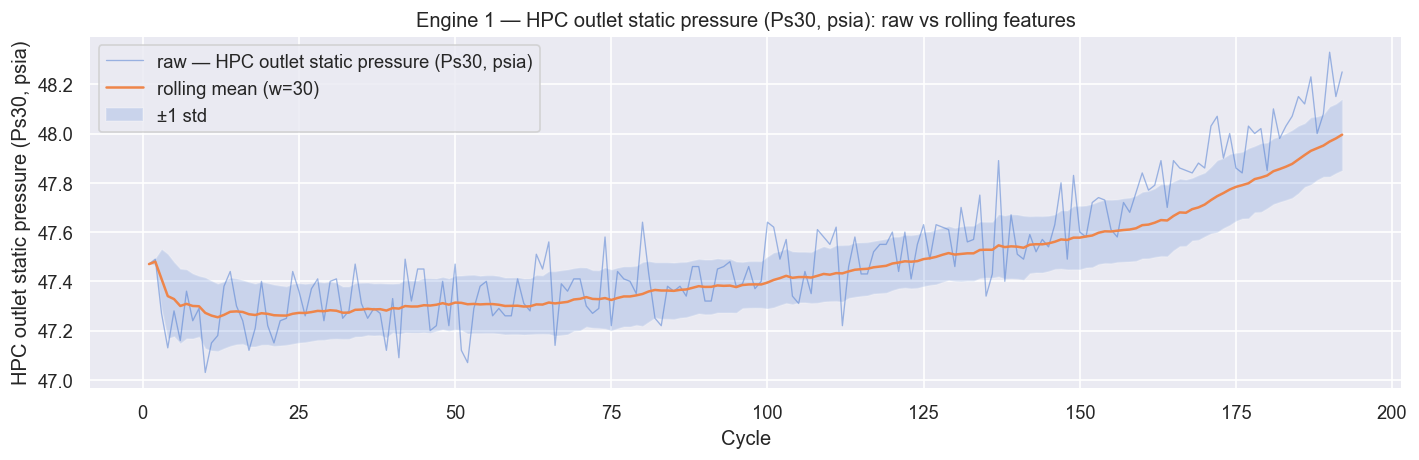

In [18]:
# Spot-check: rolling mean of sensor_11 for engine 1
# raw = mean + trend  (by definition: trend = raw - rolling_mean)
engine1 = features_df[features_df["unit_id"] == 1].copy()
engine1["sensor_11_raw"] = engine1["sensor_11_mean"] + engine1["sensor_11_trend"]

_s11_label = SENSOR_LABELS.get("sensor_11", "sensor_11")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(engine1["cycle"], engine1["sensor_11_raw"],
        label=f"raw — {_s11_label}", alpha=0.5, linewidth=0.8)
ax.plot(engine1["cycle"], engine1["sensor_11_mean"],
        label=f"rolling mean (w={WINDOW})", linewidth=1.5)
ax.fill_between(
    engine1["cycle"],
    engine1["sensor_11_mean"] - engine1["sensor_11_std"],
    engine1["sensor_11_mean"] + engine1["sensor_11_std"],
    alpha=0.2, label="±1 std"
)
ax.set_title(f"Engine 1 — {_s11_label}: raw vs rolling features")
ax.set_xlabel("Cycle")
ax.set_ylabel(_s11_label)
ax.legend()
plt.tight_layout()
plt.show()

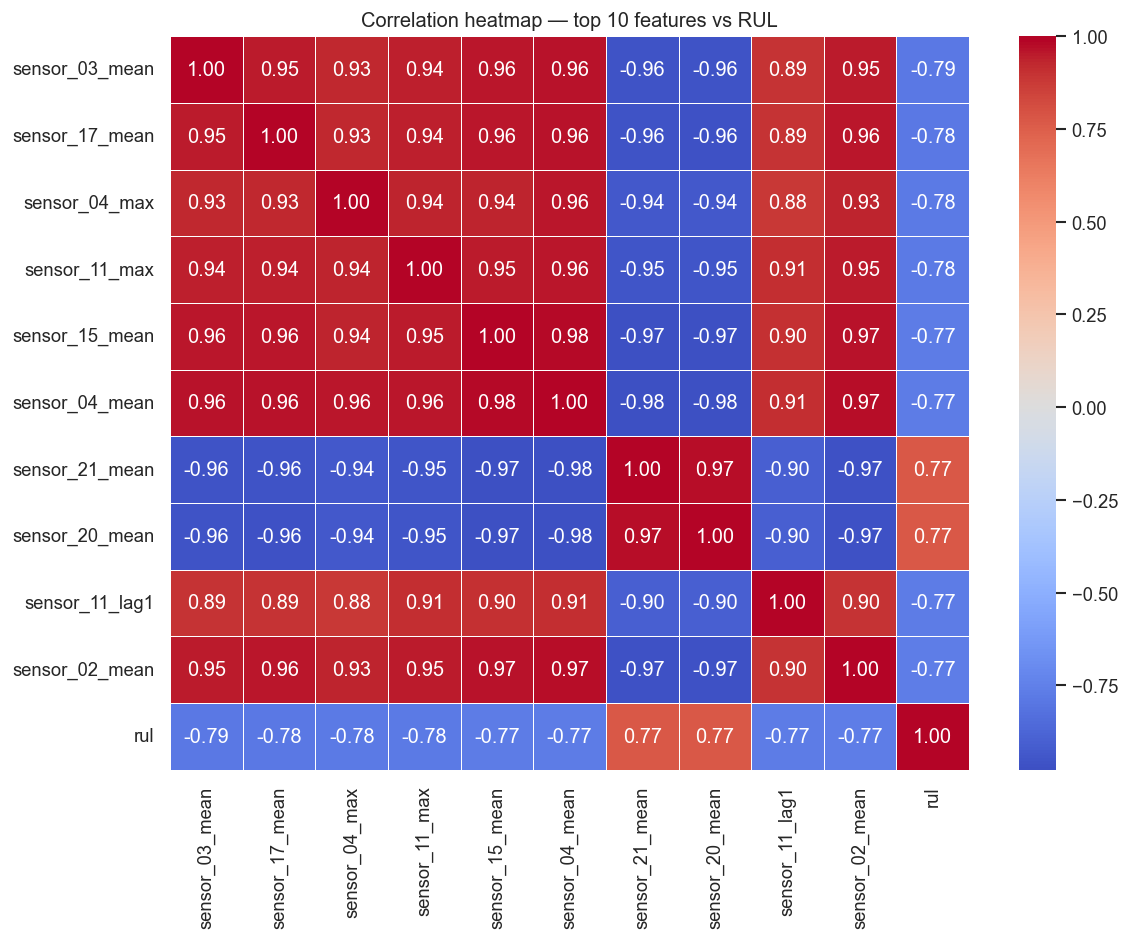


Top 10 features by |corr| with RUL:
sensor_03_mean    0.785
sensor_17_mean    0.785
sensor_04_max     0.784
sensor_11_max     0.784
sensor_15_mean    0.774
sensor_04_mean    0.772
sensor_21_mean    0.772
sensor_20_mean    0.770
sensor_11_lag1    0.769
sensor_02_mean    0.766
Name: rul, dtype: float64


In [19]:
# Correlation heatmap — top 10 features vs RUL
top10 = (
    features_df[FEATURE_COLS + ["rul"]]
    .corr()["rul"]
    .drop("rul")
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .index.tolist()
)

corr_matrix = features_df[top10 + ["rul"]].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True, fmt=".2f",
    cmap="coolwarm", center=0,
    linewidths=0.4, ax=ax,
)
ax.set_title("Correlation heatmap — top 10 features vs RUL")
plt.tight_layout()
plt.show()

print("\nTop 10 features by |corr| with RUL:")
print(features_df[FEATURE_COLS + ["rul"]].corr()["rul"].drop("rul").abs().sort_values(ascending=False).head(10).round(3))

## 5 · Train / val split by engine

We use `GroupShuffleSplit` with `groups=unit_id`.  
This guarantees **all rows of one engine go entirely to train or entirely to val** — never mixed.  
Splitting by row instead would leak future sensor readings of the same engine into training.

In [20]:
def split_by_engine(
    df: pd.DataFrame,
    val_size: float = VAL_SIZE,
    random_state: int = RANDOM_STATE,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Split a feature DataFrame into train and validation sets by engine.

    All cycles of any given engine land entirely in one split,
    preventing data leakage across time steps of the same unit.

    Args:
        df:           Feature DataFrame with a ``unit_id`` column.
        val_size:     Fraction of engines to reserve for validation.
        random_state: Seed for reproducibility.

    Returns:
        Tuple of (train_df, val_df).
    """
    gss = GroupShuffleSplit(
        n_splits=1,
        test_size=val_size,
        random_state=random_state,
    )
    groups = df["unit_id"].values
    train_idx, val_idx = next(gss.split(df, groups=groups))

    train_df = df.iloc[train_idx].reset_index(drop=True)
    val_df   = df.iloc[val_idx].reset_index(drop=True)

    log.info(
        "Train: %d rows (%d engines) | Val: %d rows (%d engines)",
        len(train_df), train_df["unit_id"].nunique(),
        len(val_df),   val_df["unit_id"].nunique(),
    )
    return train_df, val_df


train_df, val_df = split_by_engine(features_df)

# Confirm no engine appears in both splits
overlap = set(train_df["unit_id"]) & set(val_df["unit_id"])
assert len(overlap) == 0, f"Data leakage! Engines in both splits: {overlap}"
print("No overlap between train and val engines.")

INFO | Train: 16561 rows (80 engines) | Val: 4070 rows (20 engines)


No overlap between train and val engines.


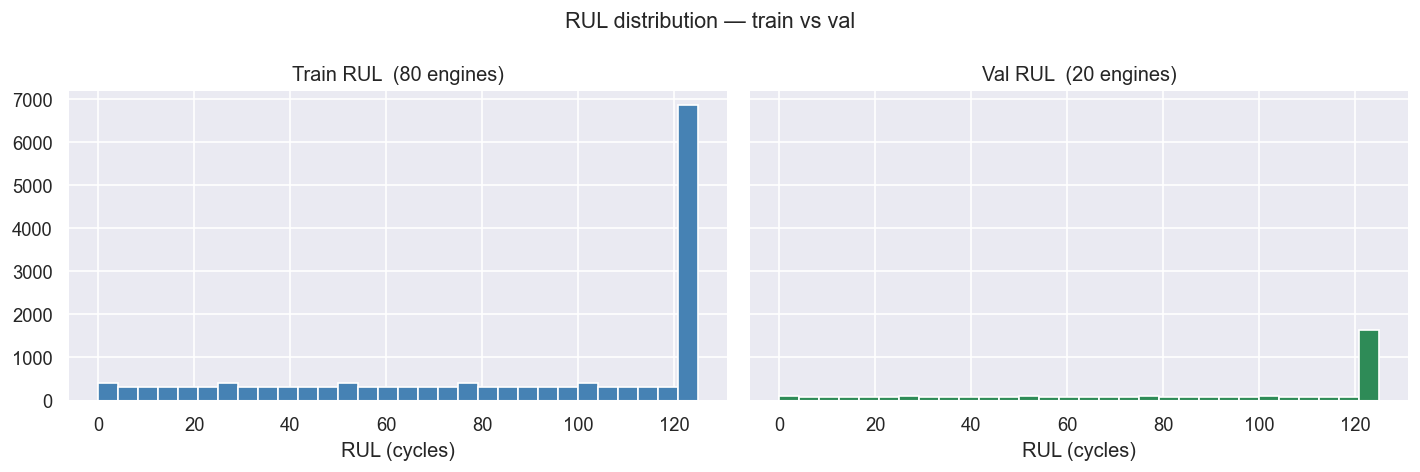

In [21]:
# Confirm RUL distributions are similar in both splits
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

axes[0].hist(train_df["rul"], bins=30, color="steelblue", edgecolor="white")
axes[0].set_title(f"Train RUL  ({train_df['unit_id'].nunique()} engines)")
axes[0].set_xlabel("RUL (cycles)")

axes[1].hist(val_df["rul"], bins=30, color="seagreen", edgecolor="white")
axes[1].set_title(f"Val RUL  ({val_df['unit_id'].nunique()} engines)")
axes[1].set_xlabel("RUL (cycles)")

plt.suptitle("RUL distribution — train vs val", fontsize=13)
plt.tight_layout()
plt.show()

## 6 · Save splits & feature metadata

In [22]:
train_df.to_parquet(DATA_PROC / "train_features.parquet", index=False)
val_df.to_parquet(DATA_PROC / "val_features.parquet",   index=False)

feature_meta = {
    "feature_cols" : FEATURE_COLS,
    "target_col"   : "rul",
    "window"       : WINDOW,
    "n_features"   : len(FEATURE_COLS),
    "train_engines": sorted(train_df["unit_id"].unique().tolist()),
    "val_engines"  : sorted(val_df["unit_id"].unique().tolist()),
}
(DATA_PROC / "feature_meta.json").write_text(json.dumps(feature_meta, indent=2))

log.info("Saved train_features.parquet, val_features.parquet, feature_meta.json")

print("\nFiles in data/:")
for f in sorted(DATA_PROC.iterdir()):
    size_kb = f.stat().st_size / 1024
    print(f"  {f.name:<40} {size_kb:>7.1f} KB")

INFO | Saved train_features.parquet, val_features.parquet, feature_meta.json



Files in data/:
  eda_meta.json                                0.4 KB
  feature_meta.json                            2.8 KB
  train_FD001_with_rul.parquet               517.7 KB
  train_features.parquet                    5310.4 KB
  val_features.parquet                      1488.6 KB


---
### Feature Engineering Summary

| Item | Value |
|------|-------|
| Sensors used | 15 |
| Features per sensor | 6 (mean, std, min, max, lag1, trend) |
| **Total features** | **90** |
| Rolling window | 30 cycles |
| Train engines | 80 |
| Val engines | 20 |
| Split method | GroupShuffleSplit — no leakage |

**Next notebook → `03_model_training.ipynb`**